# Q1. Lương khác nhau thế nào theo vùng và theo ngành?
**Người phụ trách:** Đăng

**Động lực:** người tìm việc cân nhắc chuyển vùng/ngành cần biết mức chênh lệch lương trên tin tuyển dụng.
**Phương pháp:** trung vị `salary_avg_num` (triệu VND/tháng) theo vùng × ngành; kiểm định Kruskal-Wallis và
Mann-Whitney (phi tham số vì lương lệch phải mạnh).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.cleaning import load_clean, EXPERIENCE_LEVELS, REGIONS, CATEGORY_LABELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
df["cat"] = df["category"].map(CATEGORY_LABELS)
# Tập có lương hợp lệ: bỏ "Thoả thuận" và ngoại lai
sal = df[~df["salary_negotiable"] & ~df["salary_outlier"]].copy()
print(f"Tất cả tin: {len(df):,} | Tin có lương hợp lệ: {len(sal):,}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

Tất cả tin: 36,457 | Tin có lương hợp lệ: 25,796


## 1. Phân bố lương theo vùng

,count,25%,50%,75%,mean
region,,,,,
Hà Nội,12005.0,11.0,13.0,18.0,15.5
TP.HCM,7932.0,10.0,12.0,17.0,14.8
Khác,5859.0,10.0,12.0,17.0,14.9


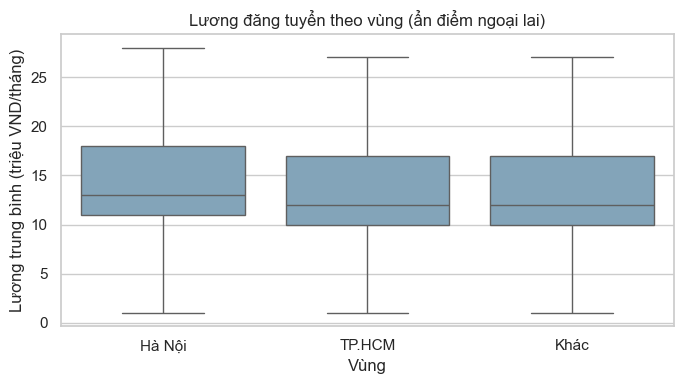

In [2]:
by_region = sal.groupby("region", observed=True)["salary_avg_num"].describe()[["count", "25%", "50%", "75%", "mean"]].round(1)
display(by_region)
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=sal, x="region", y="salary_avg_num", order=REGIONS, showfliers=False, ax=ax, color="#7aa6c2")
ax.set(xlabel="Vùng", ylabel="Lương trung bình (triệu VND/tháng)", title="Lương đăng tuyển theo vùng (ẩn điểm ngoại lai)")
savefig("q1_salary_by_region.png")

In [3]:
from scipy.stats import kruskal, mannwhitneyu
groups = [g["salary_avg_num"].values for _, g in sal.groupby("region", observed=True)]
H, p = kruskal(*groups)
print(f"Kruskal-Wallis giữa 3 vùng: H = {H:.1f}, p = {p:.2e}")
_, p_hn_hcm = mannwhitneyu(sal.loc[sal.region == "Hà Nội", "salary_avg_num"], sal.loc[sal.region == "TP.HCM", "salary_avg_num"])
print(f"Mann-Whitney Hà Nội vs TP.HCM: p = {p_hn_hcm:.2e}")

Kruskal-Wallis giữa 3 vùng: H = 126.6, p = 3.30e-28
Mann-Whitney Hà Nội vs TP.HCM: p = 2.38e-25


## 2. Lương theo ngành

,count,median,mean
cat,,,
CNTT,868,18.0,20.3
Xây dựng/BĐS,1889,16.0,18.0
Ngôn ngữ/Dịch thuật,218,15.0,15.5
Kinh doanh/CSKH,3626,14.0,16.8
Nông nghiệp/Môi trường,205,14.0,14.8
Giáo dục,747,14.0,15.5
Thiết kế/Nghệ thuật,1395,13.0,14.6
Y tế/Dược,425,13.0,17.2
Điện/Điện tử,572,12.5,14.6


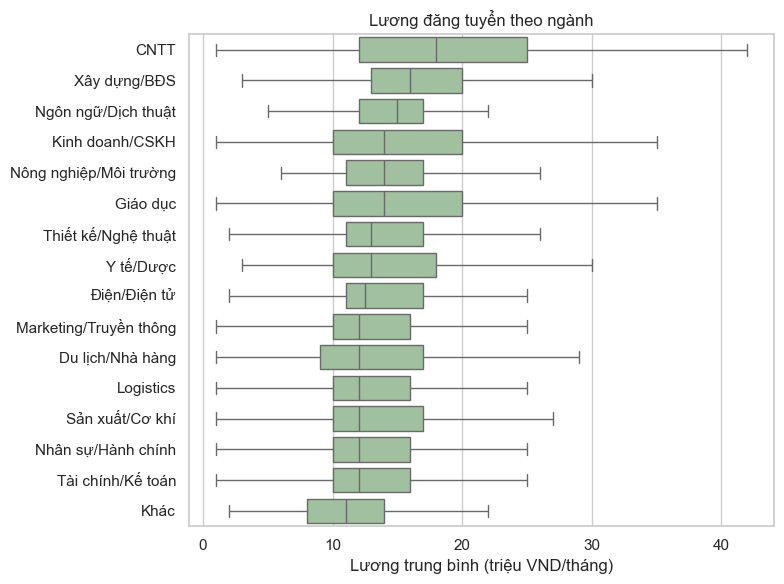

In [4]:
by_cat = sal.groupby("cat")["salary_avg_num"].agg(["count", "median", "mean"]).sort_values("median", ascending=False).round(1)
display(by_cat)
order = by_cat.index
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=sal, y="cat", x="salary_avg_num", order=order, showfliers=False, ax=ax, color="#9cc59a")
ax.set(ylabel="", xlabel="Lương trung bình (triệu VND/tháng)", title="Lương đăng tuyển theo ngành")
savefig("q1_salary_by_category.png")

## 3. Ngành × vùng

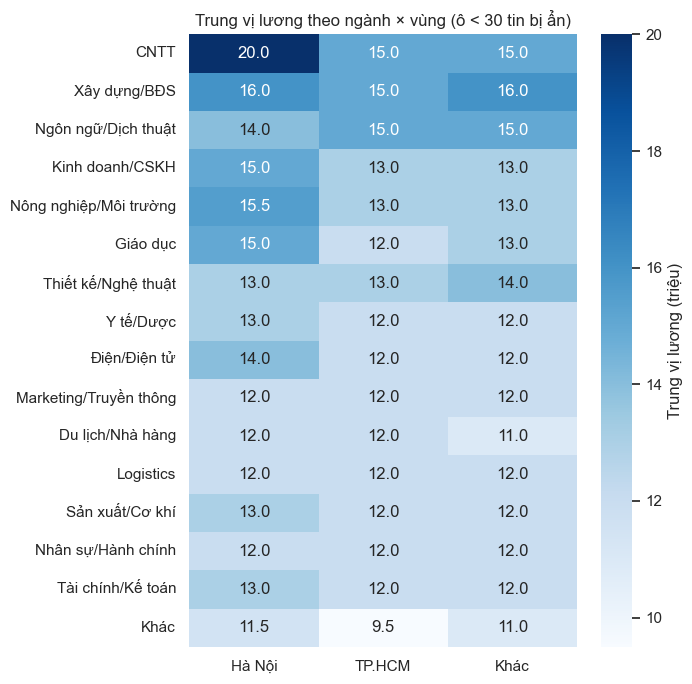

,Chênh lệch Hà Nội − tỉnh khác (triệu)
cat,
CNTT,5.0
Nông nghiệp/Môi trường,2.5
Giáo dục,2.0
Kinh doanh/CSKH,2.0
Điện/Điện tử,2.0
Y tế/Dược,1.0
Du lịch/Nhà hàng,1.0
Tài chính/Kế toán,1.0
Sản xuất/Cơ khí,1.0


In [5]:
pivot = sal.pivot_table(index="cat", columns="region", values="salary_avg_num", aggfunc="median", observed=True).loc[order]
counts = sal.pivot_table(index="cat", columns="region", values="salary_avg_num", aggfunc="count", observed=True).loc[order]
pivot = pivot.where(counts >= 30)  # ô < 30 tin không đủ tin cậy
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "Trung vị lương (triệu)"})
ax.set(xlabel="", ylabel="", title="Trung vị lương theo ngành × vùng (ô < 30 tin bị ẩn)")
savefig("q1_heatmap_category_region.png")
gap = (pivot["Hà Nội"] - pivot["Khác"]).dropna().sort_values(ascending=False)
gap.to_frame("Chênh lệch Hà Nội − tỉnh khác (triệu)").round(1)

## 4. Kết luận

In [6]:
med = sal.groupby("region", observed=True)["salary_avg_num"].median()
print(f"- Trung vị lương: Hà Nội {med['Hà Nội']:.1f}, TP.HCM {med['TP.HCM']:.1f}, tỉnh khác {med['Khác']:.1f} triệu/tháng; "
      f"khác biệt có ý nghĩa thống kê (Kruskal-Wallis p = {p:.1e}).")
print(f"- Ngành trả cao nhất (trung vị): {by_cat.index[0]} ({by_cat['median'].iloc[0]:.1f}), {by_cat.index[1]} ({by_cat['median'].iloc[1]:.1f}); "
      f"thấp nhất: {by_cat.index[-1]} ({by_cat['median'].iloc[-1]:.1f}).")
print(f"- Chênh lệch giữa ngành cao nhất và thấp nhất ≈ {by_cat['median'].iloc[0] - by_cat['median'].iloc[-1]:.1f} triệu; "
      f"giữa các vùng ≈ {med.max() - med.min():.1f} triệu.")

- Trung vị lương: Hà Nội 13.0, TP.HCM 12.0, tỉnh khác 12.0 triệu/tháng; khác biệt có ý nghĩa thống kê (Kruskal-Wallis p = 3.3e-28).
- Ngành trả cao nhất (trung vị): CNTT (18.0), Xây dựng/BĐS (16.0); thấp nhất: Khác (11.0).
- Chênh lệch giữa ngành cao nhất và thấp nhất ≈ 7.0 triệu; giữa các vùng ≈ 1.0 triệu.


**Hạn chế chung:** dữ liệu chỉ từ TopCV (2025), là **lương đăng tuyển** (không phải lương thực nhận),
và ~29% tin không công bố lương. Kết luận chỉ mô tả thị trường tin tuyển dụng trên nền tảng này.

*Nhận xét trên được sinh tự động từ số liệu — thành viên phụ trách cần đọc lại và diễn giải bằng lời của mình.*